# 🧪 Laboratorio Clase 4 · Tú decides el umbral

**Módulo II – Navegando por los componentes de la IA · Sesión 4**

Hoy vas a ponerte en el rol de líder de negocio frente a un modelo de **detección de fraude**. El modelo ya está entrenado: entrega, para cada transacción, una **probabilidad de fraude**. Tu trabajo es decidir **desde qué probabilidad se bloquea la tarjeta** (el *umbral*) y entender qué significa eso en clientes y en pesos.

**No necesitas saber programar.** Solo vas a ejecutar celdas y leer los resultados.

### Cómo usar este notebook
1. Ejecuta cada celda de código con **Shift + Enter** (o con el botón ▶ a la izquierda de la celda).
2. Si prefieres, usa el menú **Entorno de ejecución → Ejecutar todo** y luego baja leyendo.
3. Si algo falla, usa **Entorno de ejecución → Reiniciar y ejecutar todo**.

> Los datos son **sintéticos** (inventados con fines docentes). Ninguna persona real está en este laboratorio.

## Paso 1 · Preparar las herramientas
Una **librería** es un paquete de código que otras personas ya escribieron. La cargamos para no programar todo desde cero. Por ejemplo, `pandas` maneja tablas, `matplotlib` dibuja gráficos y `scikit-learn` entrena modelos. Más adelante, `shap` reparte el crédito de una predicción y `lime` intenta contar esa misma predicción con una regla simple.

Esta celda carga las librerías que usaremos. Tarda unos segundos.

In [10]:
# Paso 1: cargar herramientas (si ves un ✅ al final, todo salió bien)
import importlib.util, subprocess, sys
if importlib.util.find_spec("shap") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
if importlib.util.find_spec("lime") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lime"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
import ipywidgets as widgets
from ipywidgets import interact
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

def pesos(x):
    # Formato chileno: 1.234.567
    return "$" + f"{x:,.0f}".replace(",", ".")

print("✅ Herramientas listas")

✅ Herramientas listas


## Paso 2 · Los datos: 20.000 transacciones de un banco ficticio
Los datos son **sintéticos**: el propio notebook los genera al azar, siguiendo reglas parecidas a las de un fraude real. Usamos una **semilla** (el número 42): un valor fijo que hace que el azar se repita igual. Así, todos en la sala verán exactamente los mismos números.

Cada fila es una compra con tarjeta. Las columnas son las pistas que usa el modelo:

| Columna | Qué significa |
|---|---|
| `monto_clp` | Monto de la compra en pesos |
| `hora_del_dia` | Hora de la compra (0 a 23) |
| `distancia_km` | Distancia entre el lugar de la compra y el domicilio del cliente |
| `intentos_fallidos_24h` | Intentos fallidos con la tarjeta en las últimas 24 horas |
| `antiguedad_cliente_meses` | Hace cuántos meses es cliente |
| `compra_internacional` | 1 si la compra es en el extranjero |
| `comercio_nuevo` | 1 si el cliente nunca había comprado en ese comercio |
| `es_fraude` | La respuesta real: 1 = fraude, 0 = compra legítima |

Las siete primeras columnas son las **variables**: la información que el modelo observa. La última, `es_fraude`, es la **etiqueta**: la respuesta correcta que el modelo intenta adivinar.

Fíjate en el resultado de la celda: solo cerca del 2% de las transacciones es fraude. Cuando un caso es así de raro, decimos que los datos están **desbalanceados**. Esto será clave en el Paso 4.

In [11]:
# Paso 2: crear el set de datos sintético (siempre sale igual gracias a la "semilla" 42)
rng = np.random.default_rng(42)
n = 20_000
datos = pd.DataFrame({
    "monto_clp": np.round(rng.lognormal(mean=10.2, sigma=1.0, size=n), -2),
    "hora_del_dia": rng.integers(0, 24, n),
    "distancia_km": np.round(rng.exponential(8, n), 1),
    "intentos_fallidos_24h": rng.poisson(0.15, n),
    "antiguedad_cliente_meses": rng.integers(1, 241, n),
    "compra_internacional": rng.binomial(1, 0.08, n),
    "comercio_nuevo": rng.binomial(1, 0.30, n),
})
riesgo = (-7.2
          + 1.6 * np.log1p(datos["monto_clp"] / 50_000)
          + 2.0 * (datos["hora_del_dia"] <= 5)
          + 0.06 * np.minimum(datos["distancia_km"], 60)
          + 1.6 * datos["intentos_fallidos_24h"]
          - 0.012 * datos["antiguedad_cliente_meses"]
          + 2.4 * datos["compra_internacional"]
          + 1.4 * datos["comercio_nuevo"]
          + rng.normal(0, 0.5, n))
datos["es_fraude"] = rng.binomial(1, 1 / (1 + np.exp(-riesgo)))

print(f"Transacciones: {n:,}".replace(",", "."))
print(f"Fraudes: {datos['es_fraude'].sum()} ({datos['es_fraude'].mean():.1%} del total)")
datos.head(8)

Transacciones: 20.000
Fraudes: 379 (1.9% del total)


,monto_clp,hora_del_dia,distancia_km,intentos_fallidos_24h,antiguedad_cliente_meses,compra_internacional,comercio_nuevo,es_fraude
0,36500.0,8,19.2,0,80,0,0,0
1,9500.0,8,6.0,0,80,0,0,0
2,57000.0,0,7.3,0,211,0,0,0
3,68900.0,22,3.8,0,120,0,0,0
4,3800.0,20,4.6,1,69,0,0,0
5,7300.0,6,25.9,0,94,0,0,0
6,30600.0,3,7.3,1,64,0,0,0
7,19600.0,20,14.0,0,217,0,0,0


## Paso 3 · El equipo técnico entrena el modelo
Un **modelo de Machine Learning** (ML, aprendizaje automático) es un programa que aprende patrones a partir de ejemplos, en vez de seguir reglas escritas a mano. Aquí aprende qué combinaciones de variables suelen acompañar a un fraude.

**Entrenar** es mostrarle al modelo transacciones junto con su respuesta (`es_fraude`) para que encuentre esos patrones. **Evaluar** es probarlo con transacciones que nunca vio y comparar lo que predice con la realidad. Por eso separamos los datos en dos mitades: una para entrenar y otra para evaluar. Evaluar con los mismos ejemplos del entrenamiento sería como tomar una prueba cuyas respuestas ya conoces.

Usamos **Gradient Boosting**, un tipo de modelo que combina cientos de **árboles de decisión** pequeños. Cada árbol es una serie de preguntas simples, como *¿la compra es de madrugada?* o *¿el monto supera cierto valor?*. Cada árbol nuevo corrige los errores de los anteriores.

El modelo no responde *sí* o *no*. Para cada transacción entrega una **probabilidad de fraude**, un número entre 0 y 1. Por ejemplo, 0.85 equivale a 85% de probabilidad (Python usa punto decimal, no coma).

In [12]:
# Paso 3: entrenar el modelo (Gradient Boosting, un clásico del Machine Learning)
X = datos.drop(columns="es_fraude")
y = datos["es_fraude"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0, stratify=y)

modelo = GradientBoostingClassifier(random_state=0).fit(X_train, y_train)
prob = modelo.predict_proba(X_test)[:, 1]   # probabilidad de fraude de cada transacción
y_real = y_test.to_numpy()

print("✅ Modelo entrenado.")
print(f"Lo evaluaremos sobre {len(X_test):,} transacciones nuevas".replace(",", "."), f"(de ellas, {y_real.sum()} son fraude).")

✅ Modelo entrenado.
Lo evaluaremos sobre 10.000 transacciones nuevas (de ellas, 189 son fraude).


## Paso 4 · La trampa de la "exactitud"
La **exactitud** (en inglés, *accuracy*) es el porcentaje de transacciones en que el modelo acierta, sumando fraudes y compras legítimas. Parece la medida natural, pero tiene una trampa cuando el fraude es raro.

Un modelo con 90% de exactitud se equivoca en el 10% restante. La pregunta clave es: *¿qué tipo de error estamos cometiendo en ese 10%?* Mira lo que logra un "modelo" tramposo que responde siempre *no es fraude*:

In [13]:
# Paso 4: un "modelo" que nunca detecta fraude
exactitud_ingenua = (y_real == 0).mean()
print(f"Un 'modelo' que dice SIEMPRE 'no es fraude' tiene {exactitud_ingenua:.1%} de exactitud...")
print("...y no atrapa ni un solo fraude. Por eso la exactitud sola engaña cuando el fraude es raro.")

Un 'modelo' que dice SIEMPRE 'no es fraude' tiene 98.1% de exactitud...
...y no atrapa ni un solo fraude. Por eso la exactitud sola engaña cuando el fraude es raro.


## Antes de decidir: cinco conceptos clave
Necesitas estos cinco conceptos para leer el panel del Paso 5.

### 1. Umbral
El modelo entrega una probabilidad, pero el banco debe tomar una acción: bloquear la tarjeta o no. El **umbral** es el punto de corte. Con umbral 0.30, se bloquea toda transacción con probabilidad de fraude igual o mayor a 30%. Un umbral bajo bloquea más tarjetas; un umbral alto bloquea menos.

### 2. Los cuatro resultados posibles
Al comparar la decisión con la realidad, cada transacción cae en una de cuatro casillas. Esta tabla se llama **matriz de confusión**.

| | Era fraude | Era legítima |
|---|---|---|
| **Bloqueamos** | **VP**, verdadero positivo: fraude atrapado | **FP**, falso positivo: cliente bueno bloqueado (falsa alarma) |
| **No bloqueamos** | **FN**, falso negativo: fraude que se escapó | **VN**, verdadero negativo: cliente bueno sin molestia |

*Positivo* significa que el modelo dio la alarma de fraude. *Verdadero* o *falso* indica si esa decisión fue correcta.

### 3. Precisión
De todas las alarmas que dimos, ¿qué porcentaje era fraude de verdad?

**Precisión = VP / (VP + FP)**

Ejemplo: bloqueamos 100 tarjetas y 60 eran fraude. La precisión es 60%. Una precisión baja significa muchas falsas alarmas y muchos clientes molestos.

### 4. Recall
De todos los fraudes que ocurrieron, ¿qué porcentaje atrapamos?

**Recall = VP / (VP + FN)**

Ejemplo: hubo 200 fraudes y atrapamos 150. El recall es 75%. Un recall bajo significa que se escapa mucho fraude. En español también se llama **sensibilidad**; usamos *recall* porque es el término habitual en la industria.

### 5. El tira y afloja, y el costo
Bajar el umbral sube el recall (atrapamos más fraude), pero baja la precisión (damos más falsas alarmas). Subir el umbral hace lo contrario. Ningún umbral mejora todo a la vez. Para elegir, le ponemos precio a cada tipo de error:

**Costo total = (fraudes que se escaparon × costo de un fraude) + (clientes buenos bloqueados × costo de una falsa alarma)**

En este ejercicio, los aciertos (VP y VN) no tienen costo.

## Paso 5 · Tú decides 🎛️
Mueve los controles y observa qué pasa. Suelta el control para que se actualice.

- **Umbral**: desde qué probabilidad bloqueamos la tarjeta. Bajo = bloqueamos más; alto = bloqueamos menos.
- **Costo de un fraude no detectado**: lo que pierde el banco cuando un fraude se escapa (un FN).
- **Costo de una falsa alarma**: llamada al cliente, cliente molesto, compra perdida (un FP).

**Cómo leer el resultado.** Las cuatro primeras líneas son las casillas de la matriz de confusión: fraudes atrapados (VP), fraudes que se escaparon (FN), clientes buenos bloqueados (FP) y clientes buenos sin molestia (VN). Debajo aparecen la precisión, el recall y la exactitud, calculados con esas cuatro cifras.

**Cómo leer el gráfico.** El eje horizontal es el umbral; el eje vertical es el costo total en millones de pesos. La curva azul muestra el costo de cada umbral posible. La línea roja es tu elección. La línea verde punteada marca el umbral más barato.

> ¿No aparecen los controles? Escribe en una celda nueva, por ejemplo, `panel(umbral=0.20)` y ejecútala.

In [16]:
# Paso 5: panel interactivo
UMBRALES = np.round(np.arange(0.01, 1.00, 0.01), 2)

def evaluar(umbral, costo_fraude, costo_falsa_alarma):
    bloquear = prob >= umbral
    vp = int((bloquear & (y_real == 1)).sum())    # fraudes atrapados
    fn = int((~bloquear & (y_real == 1)).sum())   # fraudes que se escaparon
    fp = int((bloquear & (y_real == 0)).sum())    # clientes buenos bloqueados
    vn = int((~bloquear & (y_real == 0)).sum())   # clientes buenos sin molestia
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    recall = vp / (vp + fn) if (vp + fn) else 0.0
    exactitud = (vp + vn) / len(y_real)
    costo = fn * costo_fraude + fp * costo_falsa_alarma
    return dict(vp=vp, fn=fn, fp=fp, vn=vn, precision=precision,
                recall=recall, exactitud=exactitud, costo=costo)

def panel(umbral=0.50, costo_fraude=300_000, costo_falsa_alarma=15_000):
    r = evaluar(umbral, costo_fraude, costo_falsa_alarma)
    print(f"UMBRAL ELEGIDO: {umbral:.2f}\n")
    print(f"  ✅ Fraudes atrapados ............ {r['vp']:>6}")
    print(f"  ❌ Fraudes que se escaparon ..... {r['fn']:>6}")
    print(f"  ⚠️  Clientes buenos bloqueados ... {r['fp']:>6}")
    print(f"  😊 Clientes buenos sin molestia . {r['vn']:>6}\n")
    print(f"  Precisión: {r['precision']:.0%}  (de cada 100 alertas, cuántas son fraude de verdad)")
    print(f"  Recall:    {r['recall']:.0%}  (de cada 100 fraudes, cuántos atrapamos)")
    print(f"  Exactitud: {r['exactitud']:.1%}")
    print(f"\n  💰 COSTO TOTAL DE LOS ERRORES: {pesos(r['costo'])}")

    costos = [evaluar(u, costo_fraude, costo_falsa_alarma)["costo"] for u in UMBRALES]
    mejor = UMBRALES[int(np.argmin(costos))]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(UMBRALES, np.array(costos) / 1e6, color="#1F5AA6", linewidth=2)
    ax.axvline(umbral, color="#D62828", linewidth=2, label=f"Tu umbral ({umbral:.2f})")
    ax.axvline(mejor, color="#2A9D8F", linestyle="--", linewidth=1.5, label=f"Menor costo ({mejor:.2f})")
    ax.set_xlabel("Umbral")
    ax.set_ylabel("Costo total (millones CLP)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.show()

interact(
    panel,
    umbral=widgets.FloatSlider(value=0.50, min=0.01, max=0.99, step=0.01,
                               description="Umbral", continuous_update=False),
    costo_fraude=widgets.IntSlider(value=300_000, min=50_000, max=2_000_000, step=50_000,
                                   description="$ fraude", continuous_update=False),
    costo_falsa_alarma=widgets.IntSlider(value=15_000, min=1_000, max=100_000, step=1_000,
                                         description="$ falsa alarma", continuous_update=False),
);

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Umbral', max=0.99, min=0.01…

## Paso 6 · ¿Qué umbral conviene más?
Comparemos dos criterios: el umbral que da **mayor exactitud** y el que da **menor costo para el negocio**. La celda prueba los 99 umbrales posibles (de 0.01 a 0.99) y elige el mejor según cada criterio.

**Cómo leer la tabla.** Cada columna es un umbral candidato. Compara sobre todo el recall, los fraudes que se escaparon y el costo total. Puedes cambiar los costos en las dos primeras líneas de la celda y volver a ejecutarla.

In [15]:
# Paso 6: comparar criterios (cambia estos dos números si quieres)
COSTO_FRAUDE = 300_000
COSTO_FALSA_ALARMA = 15_000

tabla = pd.DataFrame([{"umbral": u, **evaluar(u, COSTO_FRAUDE, COSTO_FALSA_ALARMA)} for u in UMBRALES])
fila_exactitud = tabla.loc[tabla["exactitud"].idxmax()]
fila_costo = tabla.loc[tabla["costo"].idxmin()]

resumen = pd.DataFrame({
    "Mayor exactitud": fila_exactitud,
    "Menor costo": fila_costo,
}).loc[["umbral", "exactitud", "precision", "recall", "vp", "fn", "fp", "costo"]]
resumen.index = ["Umbral", "Exactitud", "Precisión", "Recall", "Fraudes atrapados",
                 "Fraudes que se escaparon", "Clientes buenos bloqueados", "Costo total (CLP)"]

def formato(fila, valor):
    if fila in ("Exactitud", "Precisión", "Recall"):
        return f"{valor:.1%}"
    if fila == "Costo total (CLP)":
        return pesos(valor)
    if fila == "Umbral":
        return f"{valor:.2f}"
    return f"{int(valor)}"

resumen = pd.DataFrame({col: [formato(f, v) for f, v in resumen[col].items()] for col in resumen.columns},
                       index=resumen.index)
ahorro = fila_exactitud["costo"] - fila_costo["costo"]
print(f"Elegir por costo en vez de por exactitud ahorra {pesos(ahorro)} en esta muestra.\n")
resumen

Elegir por costo en vez de por exactitud ahorra $18.990.000 en esta muestra.



,Mayor exactitud,Menor costo
Umbral,0.63,0.04
Exactitud,98.2%,92.8%
Precisión,60.0%,15.2%
Recall,11.1%,61.4%
Fraudes atrapados,21,116
Fraudes que se escaparon,168,73
Clientes buenos bloqueados,14,648
Costo total (CLP),$50.610.000,$31.620.000


## Paso 7 · Abrir la caja negra con SHAP 🔍
Un modelo como Gradient Boosting combina cientos de árboles. Nadie puede leer su lógica completa a simple vista; por eso decimos que es una **caja negra**. Esto es un problema cuando hay que justificar una decisión ante un cliente o una autoridad. La **explicabilidad** busca responder *¿por qué el modelo decidió esto?*

**SHAP** (*SHapley Additive exPlanations*, explicaciones aditivas de Shapley) es un método de explicabilidad. Toma una sola predicción y calcula cuánto subió o bajó la probabilidad de fraude cada variable del cliente. Se basa en los **valores de Shapley**, una idea de teoría de juegos para repartir un resultado de forma justa entre varios participantes.

Elegimos a un **cliente bueno que el modelo bloqueó** (un falso positivo, FP) y le preguntamos al modelo *¿por qué?* La celda tarda unos segundos.

Cómo leer el gráfico:
- Parte abajo en **E[f(x)]**: la probabilidad promedio de fraude que el modelo asigna a una transacción típica. Es el punto de partida.
- Cada barra **roja** empuja la probabilidad hacia arriba (más sospechoso); cada barra **azul** la baja. El número de la barra indica cuánto empuja.
- Arriba, **f(x)** es la probabilidad final que dio el modelo para este cliente: el punto de partida más todas las barras.

Esa cuenta responde cuánto crédito recibe cada variable frente al promedio. No responde si una regla corta, armada solo con casos parecidos a este cliente, cuenta la misma decisión. Esa segunda pregunta está en el Paso 8. Con Shapley solo, el bloqueo no queda justificado.

Probabilidad de fraude según el modelo: 97% (umbral 0.04) → BLOQUEADO
En la realidad, esta compra era LEGÍTIMA.

                            valor
monto_clp                 86000.0
hora_del_dia                  4.0
distancia_km                  4.7
intentos_fallidos_24h         2.0
antiguedad_cliente_meses     52.0
compra_internacional          1.0
comercio_nuevo                0.0


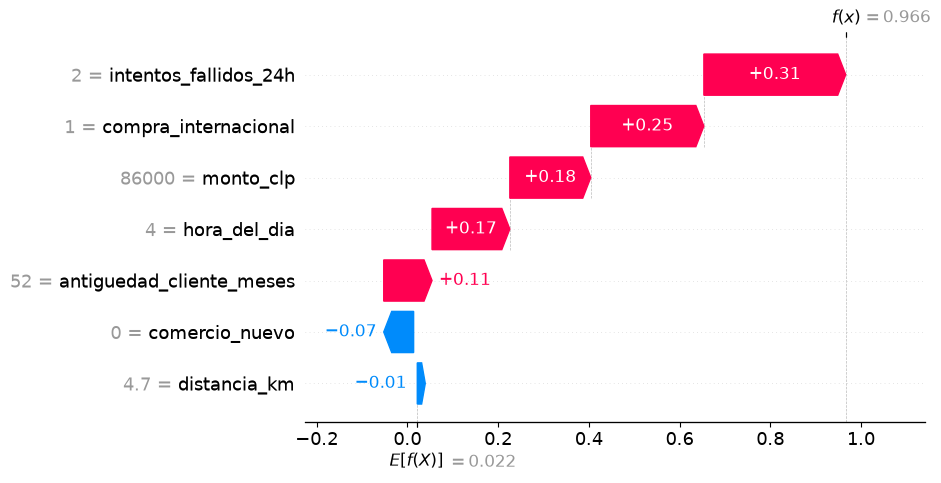

In [17]:
# Paso 7: explicar UNA decisión con SHAP
UMBRAL_ELEGIDO = float(fila_costo["umbral"])   # usamos el umbral de menor costo del Paso 6

explicador = shap.TreeExplainer(modelo, data=X_train.sample(100, random_state=0),
                                model_output="probability")

falsos_positivos = np.where((prob >= UMBRAL_ELEGIDO) & (y_real == 0))[0]
i = falsos_positivos[np.argmax(prob[falsos_positivos])]   # el cliente bueno más "sospechoso"
cliente = X_test.iloc[[i]]

print(f"Probabilidad de fraude según el modelo: {prob[i]:.0%} (umbral {UMBRAL_ELEGIDO:.2f}) → BLOQUEADO")
print("En la realidad, esta compra era LEGÍTIMA.\n")
print(cliente.T.rename(columns={cliente.index[0]: "valor"}).to_string())

explicacion = explicador(cliente)
shap.plots.waterfall(explicacion[0], max_display=8)

## Paso 8 · La misma decisión con LIME

El gráfico SHAP del Paso 7 responde una pregunta concreta. Toma la diferencia entre la probabilidad promedio y la probabilidad de este cliente, y reparte esa diferencia entre las variables. Los valores de Shapley cierran la cuenta: el punto de partida más las barras es la probabilidad del modelo. Por eso el gráfico se ve completo.

Esa cuenta no basta para defender el bloqueo.

El reparto depende del fondo de comparación. En el Paso 7 ese fondo es una muestra de 100 transacciones de entrenamiento. Otra muestra mueve las barras. El crédito de una variable es crédito frente a ese fondo.

El reparto pone un número por variable y los suma. El modelo puede estar reaccionando a una combinación, por ejemplo madrugada junto con compra internacional y varios intentos fallidos. Un número por variable no muestra la combinación. Aun así, la suma cierra, y la cuenta puede verse terminada aunque la razón sea conjunta.

Además, SHAP en este laboratorio mira por dentro del modelo. `TreeExplainer` usa la estructura de los árboles. Un cliente y un regulador piden otra cosa: una frase que se pueda leer en voz alta, válida para casos parecidos a este, y que no exija abrir la caja negra.

**LIME** (*Local Interpretable Model-agnostic Explanations*) construye esa frase.

- *Local*: la explicación vale para este cliente y su vecindario, no para todo el banco.
- *Interpretable*: la explicación es una regla corta.
- *Model-agnostic*: LIME no mira por dentro del modelo. Le basta con pedirle probabilidades. Sirve para Gradient Boosting y para cualquier otro modelo que entregue probabilidades.

El procedimiento, sobre el mismo cliente del Paso 7:

1. Crea miles de transacciones parecidas a este cliente. Cambia un poco cada variable. Ese conjunto es el **vecindario**.
2. Pide al modelo la probabilidad de fraude de cada transacción del vecindario.
3. Ajusta una **regresión lineal**. Las transacciones más cercanas al cliente pesan más. Las lejanas pesan menos.
4. Traduce cada coeficiente a una regla, por ejemplo `hora_del_dia <= 6` o `compra_internacional=1`.

Esa recta es un modelo chico. Intenta imitar al modelo grande solo en este vecindario. Hay que medir si la imitación alcanza.

### Cómo leer el resultado

La celda imprime dos probabilidades. La primera es la del modelo. La segunda es la de la recta, para este mismo cliente. Al lado va el **R² ponderado**: qué tan bien la recta imita al modelo dentro del vecindario. En ese cálculo pesan más las transacciones parecidas a este cliente. Cerca de 1, la imitación es buena. Cerca de 0, la recta no explica más que un promedio.

Con la semilla de este laboratorio las dos probabilidades quedan lejos y el R² queda bajo. Eso no es un error de la celda. Una regla lineal corta no reproduce esta decisión. Las barras de LIME, entonces, no alcanzan para justificar el bloqueo.

El gráfico usa los mismos colores que SHAP. La barra **roja** empuja hacia fraude. La barra **azul** empuja hacia compra legítima. El número de la barra es el coeficiente de la recta. Sumar las barras no devuelve la probabilidad del modelo. La librería LIME, en su gráfico por defecto, pinta los colores al revés. Por eso el gráfico lo dibuja esta celda.

La tabla final pone lado a lado el signo de SHAP y el signo de LIME. Mismo signo quiere decir que ambos ven la variable empujando hacia el mismo lado. El orden puede cambiar. En esta semilla, SHAP asigna el mayor aporte a `intentos_fallidos_24h`. LIME asigna el mayor peso a la regla `compra_internacional=1`. Las dos lecturas pueden ser correctas a la vez, porque cada método hace una pregunta distinta. Ninguna de las dos es, por sí sola, la causa del bloqueo.

LIME también tiene límites. El vecindario depende de cuántas transacciones se inventan y de la semilla. Los rangos, como `monto_clp > 53000`, salen de cortar la variable en tramos, y el corte se ve más nítido de lo que es el modelo. Un R² bajo no dice que el bloqueo esté mal. Dice que esta explicación simple no alcanza para sostenerlo.


Probabilidad del modelo (caja negra):     97%
Probabilidad de la recta local (LIME):    21%
Fidelidad en el vecindario (R² ponderado): 0.30
Cerca de 1, la recta imita bien al modelo. Cerca de 0, la regla simple no alcanza.

Reglas del vecindario. Peso positivo = empuja a fraude:
  +0.078   compra_internacional=1
  +0.043   hora_del_dia <= 6.00
  +0.043   monto_clp > 53000.00
  +0.039   intentos_fallidos_24h > 0.00
  +0.036   antiguedad_cliente_meses <= 62.00
  -0.027   comercio_nuevo=0
  -0.000   2.30 < distancia_km <= 5.60


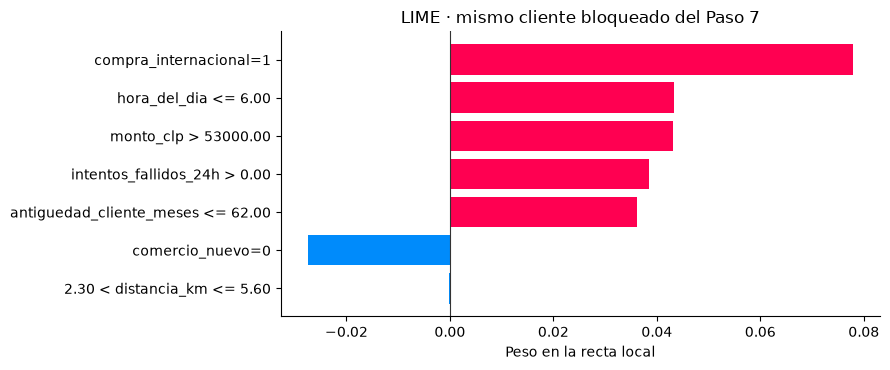

Comparación del mismo cliente. El signo dice hacia qué lado empuja la variable.


,Variable,Regla LIME,Peso LIME,Aporte SHAP,Mismo signo
0,compra_internacional,compra_internacional=1,+0.078,+0.249,sí
1,hora_del_dia,hora_del_dia <= 6.00,+0.043,+0.171,sí
2,monto_clp,monto_clp > 53000.00,+0.043,+0.178,sí
3,intentos_fallidos_24h,intentos_fallidos_24h > 0.00,+0.039,+0.313,sí
4,antiguedad_cliente_meses,antiguedad_cliente_meses <= 62.00,+0.036,+0.106,sí
5,comercio_nuevo,comercio_nuevo=0,-0.027,-0.066,sí
6,distancia_km,2.30 < distancia_km <= 5.60,-0.000,-0.008,ambas casi nulas


In [18]:
# Paso 8: la misma decisión, contada con una regla local (LIME)
# Usa el mismo cliente bloqueado del Paso 7.

def probabilidad_fraude(matriz):
    """LIME entrega una matriz sin nombres. La devolvemos como tabla para el modelo."""
    tabla = pd.DataFrame(matriz, columns=X.columns)
    return modelo.predict_proba(tabla)

categoricas = [list(X.columns).index(nombre)
               for nombre in ("compra_internacional", "comercio_nuevo")]

explicador_lime = LimeTabularExplainer(
    X_train.to_numpy(),
    feature_names=list(X.columns),
    class_names=["legítima", "fraude"],
    categorical_features=categoricas,
    discretize_continuous=True,       # traduce montos y horas a rangos legibles
    sample_around_instance=True,      # el vecindario se arma alrededor de este cliente
    feature_selection="none",          # incluye las 7 variables, para compararlas con SHAP
    random_state=0,
)

explicacion_lime = explicador_lime.explain_instance(
    cliente.to_numpy()[0],
    probabilidad_fraude,
    num_features=len(X.columns),
    num_samples=4_000,
)

prob_modelo = float(explicacion_lime.predict_proba[1])
prob_recta = float(np.asarray(explicacion_lime.local_pred).reshape(-1)[0])
print(f"Probabilidad del modelo (caja negra):     {prob_modelo:.0%}")
print(f"Probabilidad de la recta local (LIME):    {prob_recta:.0%}")
print(f"Fidelidad en el vecindario (R² ponderado): {explicacion_lime.score:.2f}")
print("Cerca de 1, la recta imita bien al modelo. Cerca de 0, la regla simple no alcanza.\n")
print("Reglas del vecindario. Peso positivo = empuja a fraude:")
for regla, peso in explicacion_lime.as_list(label=1):
    print(f"  {peso:+.3f}   {regla}")

reglas = explicacion_lime.as_list(label=1)
nombres = [regla for regla, _ in reglas][::-1]
pesos_barra = [peso for _, peso in reglas][::-1]
colores = ["#FF0051" if peso > 0 else "#008BFB" for peso in pesos_barra]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(nombres, pesos_barra, color=colores)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Peso en la recta local")
ax.set_title("LIME · mismo cliente bloqueado del Paso 7")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

def variable_de(regla):
    coincidencias = [nombre for nombre in X.columns if nombre in regla]
    if not coincidencias:
        return regla
    return max(coincidencias, key=len)

shap_serie = pd.Series(explicacion[0].values, index=list(explicacion[0].feature_names))
filas = []
for regla, peso in reglas:
    variable = variable_de(regla)
    aporte = float(shap_serie[variable])
    if abs(aporte) < 0.01 and abs(peso) < 0.01:
        mismo_signo = "ambas casi nulas"
    elif aporte * peso > 0:
        mismo_signo = "sí"
    else:
        mismo_signo = "no"
    filas.append({
        "Variable": variable,
        "Regla LIME": regla,
        "Peso LIME": f"{peso:+.3f}",
        "Aporte SHAP": f"{aporte:+.3f}",
        "Mismo signo": mismo_signo,
    })

print("Comparación del mismo cliente. El signo dice hacia qué lado empuja la variable.")
pd.DataFrame(filas)


## Para la puesta en común 💬
Anota tus respuestas; las conversaremos en la sala.

1. **¿Qué umbral minimizó el costo?** ¿Cuánto fraude se escapó y a cuántos clientes buenos bloqueaste?
2. **¿Por qué el umbral de mayor exactitud no es el de menor costo?**
3. **Con el gráfico SHAP y el gráfico LIME del mismo cliente, ¿defenderías el bloqueo ante el cliente o ante un regulador?** Mira dos cosas: si el orden de las variables coincide, y si la recta de LIME reproduce la probabilidad del modelo. (El **regulador** es la autoridad que supervisa a los bancos. En Chile es la CMF, Comisión para el Mercado Financiero.)
4. **Bonus:** sube el costo de la falsa alarma a $60.000 (cliente premium). ¿Hacia dónde se mueve el mejor umbral? ¿Qué te dice eso sobre quién debe fijar el umbral: el equipo técnico o el negocio?

> Idea fuerza: el umbral **no es una decisión técnica**; es la traducción del **apetito de riesgo** del negocio, es decir, cuánto riesgo está dispuesta a aceptar la empresa para lograr sus objetivos.

El Paso 9 cierra esta decisión con un expediente: la finalidad del sistema, una persona responsable y un texto claro para el cliente.

## Paso 9 · Cumplir con el expediente de la decisión

Los gráficos de SHAP y de LIME no cumplen el Reglamento (UE) 2024/1689, la ley europea de inteligencia artificial. Cumplir, para esta decisión, tiene dos capas. La primera mantiene el sistema dentro de su finalidad. La segunda cierra el bloqueo con un texto que una persona pueda leer, corregir y discutir.

### Capa 1 · Quedarse en la finalidad prevista

El Anexo III, punto 5(b), clasifica como de alto riesgo a los sistemas que evalúan la solvencia de una persona natural o que fijan su puntaje de crédito. El mismo punto exceptúa a los sistemas usados para detectar fraude financiero.

Este laboratorio tiene una sola finalidad prevista: estimar si una transacción con tarjeta parece fraude y proponer un bloqueo provisorio. No evalúa si el cliente puede pagar un crédito. No fija un puntaje de crédito. No pone precio a un seguro de vida o de salud. No decide el acceso a vivienda, electricidad ni telecomunicaciones.

Esa frase queda escrita en el expediente. Si el banco usa después el mismo puntaje para negar un crédito, la excepción termina y el sistema entra al régimen de alto riesgo. En ese régimen importan, entre otros, el artículo 13 (información para que el responsable del despliegue interprete la salida), el artículo 14 (supervisión humana) y el artículo 86.

El artículo 86 da a la persona afectada, ante un sistema de alto riesgo del Anexo III, un derecho a explicaciones claras y significativas sobre el papel del sistema en la decisión y sobre los elementos principales de esa decisión. El derecho nace cuando la decisión produce efectos jurídicos o afecta de forma significativa su salud, seguridad o derechos fundamentales. Mientras este modelo se use solo para detectar fraude, ese artículo no es la norma que cierra el caso. El laboratorio igual usa ese estándar, porque bloquear la tarjeta afecta a la persona y porque es la manera de explicar la salida a quien despliega el sistema.

El **responsable del despliegue** es quien usa el sistema en su actividad, aquí el banco. El **proveedor** es quien lo desarrolla. El cliente es la **persona afectada**.

### Capa 2 · Cerrar el bloqueo con cinco reglas

1. Separar la probabilidad del modelo y el umbral del negocio. El modelo estima. El negocio fija desde qué probabilidad hay bloqueo.
2. Contar como elementos principales solo las variables en que SHAP y LIME empujan hacia el mismo lado. Dejar fuera las casi nulas. No nombrar una variable como la causa: en esta semilla los métodos no coinciden en cuál pesa más.
3. Medir si la recta local reproduce la probabilidad. La institución fija una barra. En este laboratorio la barra es 0,70 de R² ponderado. Bajo esa barra, el puntaje no cierra solo un bloqueo que perjudica al cliente.
4. Exigir una persona con autoridad para mantener o levantar el bloqueo. Si lo mantiene, declara que revisó los hechos de la transacción. Sin esa declaración, el expediente queda abierto.
5. Escribir un texto para el cliente con la finalidad del sistema, el corte del negocio, los hechos que puede corregir, el límite de la explicación simple, la decisión de la persona y la vía para pedir otra revisión.

La celda usa al mismo cliente de los pasos 7 y 8. Arriba del código hay tres líneas que le corresponden a una persona, no al modelo. Puedes cambiar `DECISION_HUMANA` a `"mantener"` o `"levantar"` y volver a ejecutar.

Con la fidelidad de esta semilla, bajo la barra de 0,70, el procedimiento levanta el bloqueo provisorio. El puntaje queda como alerta, no como última palabra.

Esto es un procedimiento de aula. No es una evaluación de conformidad ni un dictamen jurídico.


In [19]:
# Paso 9: expediente de la decisión
# Estas tres líneas las completa una persona. El modelo no las completa.
FIDELIDAD_MINIMA = 0.70
REVISOR = "supervisión de fraude"
DECISION_HUMANA = "levantar"          # escribe "mantener" o "levantar"
HECHOS_REVISADOS_POR_PERSONA = True   # True solo si una persona miró la transacción

fila_cliente = cliente.iloc[0]
ficha = pd.DataFrame(filas)
se_dicen = ficha[ficha["Mismo signo"] == "sí"]
no_se_dicen = ficha[ficha["Mismo signo"] != "sí"]

def hecho_observable(variable, valor):
    if variable == "monto_clp":
        return f"el monto de la compra es {pesos(valor)}"
    if variable == "hora_del_dia":
        return f"la compra se hizo a las {int(valor):02d}:00"
    if variable == "distancia_km":
        return f"la distancia al domicilio es {valor:g} km"
    if variable == "intentos_fallidos_24h":
        n = int(valor)
        return f"hubo {n} intento fallido en 24 horas" if n == 1 else f"hubo {n} intentos fallidos en 24 horas"
    if variable == "antiguedad_cliente_meses":
        return f"el cliente tiene {int(valor)} meses de antigüedad"
    if variable == "compra_internacional":
        return "la compra es internacional" if int(valor) == 1 else "la compra es nacional"
    if variable == "comercio_nuevo":
        return "el comercio es nuevo para el cliente" if int(valor) == 1 else "el cliente ya había comprado en ese comercio"
    return f"{variable} = {valor}"

elementos = []
for _, row in se_dicen.iterrows():
    sentido = "aumenta la sospecha" if float(row["Peso LIME"]) > 0 else "disminuye la sospecha"
    elementos.append(f"{hecho_observable(row['Variable'], fila_cliente[row['Variable']])} ({sentido})")

fidelidad = float(explicacion_lime.score)
puntaje_no_cierra = fidelidad < FIDELIDAD_MINIMA
decision = DECISION_HUMANA.strip().lower()
decision_valida = decision in {"mantener", "levantar"}
puede_cerrar = decision_valida and (decision == "levantar" or HECHOS_REVISADOS_POR_PERSONA)

print("EXPEDIENTE DE LA DECISIÓN\n")
print("Finalidad prevista: detectar fraude en una transacción con tarjeta.")
print("Fuera de finalidad: solvencia, puntaje de crédito, precio de seguro de vida o de salud,")
print("acceso a vivienda, electricidad o telecomunicaciones.")
print("Clasificación de este uso: excepción del Anexo III, punto 5(b), fraude financiero.\n")
print(f"Probabilidad del modelo: {prob_modelo:.0%}")
print(f"Umbral del negocio:      {UMBRAL_ELEGIDO:.0%}")
print("Alerta automática:       bloqueo provisorio")
print(f"Fidelidad de la recta:   {fidelidad:.2f}  (barra de la institución: {FIDELIDAD_MINIMA:.2f})")
if puntaje_no_cierra:
    print("El puntaje no cierra solo el bloqueo: la recta no reproduce la probabilidad.\n")
else:
    print("La recta supera la barra fijada por la institución.\n")
print("Elementos que se pueden decir, porque ambos métodos coinciden en el signo:")
for numero, linea in enumerate(elementos, start=1):
    print(f"  {numero}. {linea}")
if len(no_se_dicen):
    print("\nQuedan fuera del texto al cliente:")
    for _, row in no_se_dicen.iterrows():
        print(f"  - {row['Variable']}: {row['Mismo signo']}")
print(f"\nRevisor: {REVISOR}")
print(f"Decisión humana: {decision if decision_valida else 'pendiente'}")
print(f"Declaró haber revisado los hechos: {'sí' if HECHOS_REVISADOS_POR_PERSONA else 'no'}")

if not puede_cerrar:
    print("\nEXPEDIENTE ABIERTO.")
    print("Falta una decisión humana válida ('mantener' o 'levantar'),")
    print("o falta la declaración de que una persona revisó los hechos antes de mantener el bloqueo.")
else:
    if decision == "levantar":
        cierre = "La supervisión levanta el bloqueo provisorio. La compra puede continuar."
    else:
        cierre = (
            "La supervisión mantiene el bloqueo después de revisar los hechos observables. "
            "El puntaje del modelo no es, por sí solo, la razón de ese cierre."
        )
    hechos = " ".join(f"({n}) {linea}." for n, linea in enumerate(elementos, start=1))
    texto = (
        "Usamos un sistema automático para detectar fraude en transacciones con tarjeta. "
        "Ese sistema no evalúa su solvencia ni decide si puede obtener crédito.\n\n"
        f"En esta compra el sistema estimó {prob_modelo:.0%} de probabilidad de fraude. "
        f"El banco había fijado el bloqueo desde {UMBRAL_ELEGIDO:.0%}. "
        "Ese corte lo define el negocio.\n\n"
        "Los datos de la compra que dos revisiones distintas marcan en el mismo sentido son: "
        f"{hechos} "
        "Puede pedir que corrijamos cualquiera de esos datos si no corresponden.\n\n"
        f"Una explicación simple, armada con casos parecidos al suyo, estima {prob_recta:.0%}, "
        f"no el {prob_modelo:.0%} del sistema. "
        "Por eso el sistema no tiene la última palabra.\n\n"
        f"{cierre} Quedó registrada a nombre de la {REVISOR}. "
        "Puede pedir una nueva revisión hecha por una persona y puede oponerse a esta decisión."
    )
    print("\nTEXTO PARA EL CLIENTE\n")
    print(texto)
    print("\nEl expediente queda cerrado con la finalidad, la decisión humana y este texto.")


EXPEDIENTE DE LA DECISIÓN

Finalidad prevista: detectar fraude en una transacción con tarjeta.
Fuera de finalidad: solvencia, puntaje de crédito, precio de seguro de vida o de salud,
acceso a vivienda, electricidad o telecomunicaciones.
Clasificación de este uso: excepción del Anexo III, punto 5(b), fraude financiero.

Probabilidad del modelo: 97%
Umbral del negocio:      4%
Alerta automática:       bloqueo provisorio
Fidelidad de la recta:   0.30  (barra de la institución: 0.70)
El puntaje no cierra solo el bloqueo: la recta no reproduce la probabilidad.

Elementos que se pueden decir, porque ambos métodos coinciden en el signo:
  1. la compra es internacional (aumenta la sospecha)
  2. la compra se hizo a las 04:00 (aumenta la sospecha)
  3. el monto de la compra es $86.000 (aumenta la sospecha)
  4. hubo 2 intentos fallidos en 24 horas (aumenta la sospecha)
  5. el cliente tiene 52 meses de antigüedad (aumenta la sospecha)
  6. el cliente ya había comprado en ese comercio (disminuye